In [1]:
# 使用python的matplotlib包和seaborn包对出租车GPS数据绘制数据统计图表
# 完成时间：2026-7-5~2026-7-7
# 练习内容:分析统计数据，并且根据数据制作及美化折线图、柱状图、箱线图等

读取数据

In [2]:
#读取GPS数据
import pandas as pd
data = pd.read_csv(r'E:/GIS_Learning/data/TaxiData-Sample.csv',header = None)
data.columns = ['VehicleNum', 'Stime', 'Lng', 'Lat', 'OpenStatus', 'Speed']
data.head(5)

,VehicleNum,Stime,Lng,Lat,OpenStatus,Speed
0,22271,22:54:04,114.167000,22.718399,0,0
1,22271,18:26:26,114.190598,22.647800,0,4
2,22271,18:35:18,114.201401,22.649700,0,0
3,22271,16:02:46,114.233498,22.725901,0,24
4,22271,21:41:17,114.233597,22.720900,0,19


In [3]:
#读取OD数据
TaxiOD = pd.read_csv(r'E:/GIS_Learning/data/TaxiOD-Sample-finish.csv')
TaxiOD.columns = ['VehicleNum', 'Stime', 'SLng', 'SLat', 
       'ELng', 'ELat','Etime']
TaxiOD.head(5)

,VehicleNum,Stime,SLng,SLat,ELng,ELat,Etime
0,22334,00:17:58,114.084915,22.540850,00:18:56,114.084915,22.540850
1,22334,00:44:47,114.056236,22.633383,02:38:35,114.091637,22.543200
2,22334,02:46:52,114.093498,22.554382,03:58:46,114.038818,22.553232
3,22334,04:13:57,114.052299,22.604366,06:30:11,114.031250,22.519550
4,22334,06:41:19,114.067886,22.521299,06:49:40,114.063034,22.534634


每小时GPS数据量绘图

In [4]:
# 要集计每小时的数据，那就需要有一列的内容表示数据哪个每小时，然后以那列数据为集计。因此这里我们对data的Stime列处理，得到该时间所属的小时
# 集计：按维度拆分 → 每组做统计 → 合并成汇总表

In [5]:
#计时
import time
timeflag = time.time() # 返回当前时刻距离 Unix 纪元（1970 年 1 月 1 日 00:00:00 UTC 标准时间） 的总秒数，返回值为浮点数
#方法1：把时间当成字符串，用列自带的str方法，取前两位
# .str.slice(0,2)是 pandas 的字符串向量化操作，直接批量截取每个时间字符串的前 2 位（小时部分），速度最快。适合时间格式固定、无需复杂时间运算的场景
data['Hour'] = data['Stime'].str.slice(0,2)
#计算耗时
print('方法1',time.time()-timeflag,'s')
timeflag = time.time()

#方法2：把时间当成字符串，遍历取字符串前两位
# apply()会逐行遍历数据，执行括号内传入的参数
data['Hour'] = data['Stime'].apply(lambda r:r[:2])
# lambda r:r[:2]：r 是形参，代表 Stime 列里每一行的单个元素（也就是单个时间字符串）
# r[:2] 是字符串切片操作，Python 中字符串切片遵循「左闭右开」规则，[:2] 表示取从索引 0 到索引 2 之前的字符，也就是字符串的前两位字符

#计算耗时
print('方法2',time.time()-timeflag,'s')
timeflag = time.time()

"""
#方法3：转换为时间格式，后提取小时（非常慢）
# 先通过pd.to_datetime()把字符串转为标准时间类型，再提取hour属性。时间类型转换的计算开销很大，因此速度最慢；优点是支持跨天计算、时区处理等复杂时间运算
data['Hour'] = pd.to_datetime(data['Stime']).apply(lambda r:r.hour)
#计算耗时
print('方法3',time.time()-timeflag,'s')
timeflag = time.time()
"""

方法1 0.24676871299743652 s
方法2 0.2229783535003662 s


"\n#方法3：转换为时间格式，后提取小时（非常慢）\n# 先通过pd.to_datetime()把字符串转为标准时间类型，再提取hour属性。时间类型转换的计算开销很大，因此速度最慢；优点是支持跨天计算、时区处理等复杂时间运算\ndata['Hour'] = pd.to_datetime(data['Stime']).apply(lambda r:r.hour)\n#计算耗时\nprint('方法3',time.time()-timeflag,'s')\ntimeflag = time.time()\n"

In [6]:
"""
df.groupby() 是 pandas 中最核心的分组聚合函数，它遵循「拆分 → 应用 → 合并」（Split-Apply-Combine）的逻辑：
拆分：按照指定的列，把整张数据表分成若干个独立的小组
应用：对每个小组分别执行统计计算（求和、求平均、计数等）
合并：把所有小组的计算结果拼接成一张新表返回
常用：
.count()	统计每组的记录数
.sum()	每组求和
.mean()	每组求平均值
.max() / .min()	每组最大值 / 最小值
.agg([...])	同时执行多个聚合计算
"""

'\ndf.groupby() 是 pandas 中最核心的分组聚合函数，它遵循「拆分 → 应用 → 合并」（Split-Apply-Combine）的逻辑：\n拆分：按照指定的列，把整张数据表分成若干个独立的小组\n应用：对每个小组分别执行统计计算（求和、求平均、计数等）\n合并：把所有小组的计算结果拼接成一张新表返回\n常用：\n.count()\t统计每组的记录数\n.sum()\t每组求和\n.mean()\t每组求平均值\n.max() / .min()\t每组最大值 / 最小值\n.agg([...])\t同时执行多个聚合计算\n'

In [7]:
# 目标：按小时分组，统计每个小时的 GPS 轨迹条数，得到 0-23 点的数据量分布
# 分组时直接提取小时，只对vehicleNum一列计数，最后重置索引
hourcount = data.groupby(data['Stime'].apply(lambda r:r[:2]))['VehicleNum'].count().reset_index()
"""
groupby('Hour')：按 Hour 列的值分组，相同时刻的行会被分到同一组。
.count()：统计每组的记录数量。
.reset_index()：分组后 Hour 会变成行索引，重置索引后 Hour 变回普通数据列，方便后续绘图时作为 x 轴。
"""

"\ngroupby('Hour')：按 Hour 列的值分组，相同时刻的行会被分到同一组。\n.count()：统计每组的记录数量。\n.reset_index()：分组后 Hour 会变成行索引，重置索引后 Hour 变回普通数据列，方便后续绘图时作为 x 轴。\n"

开始绘图

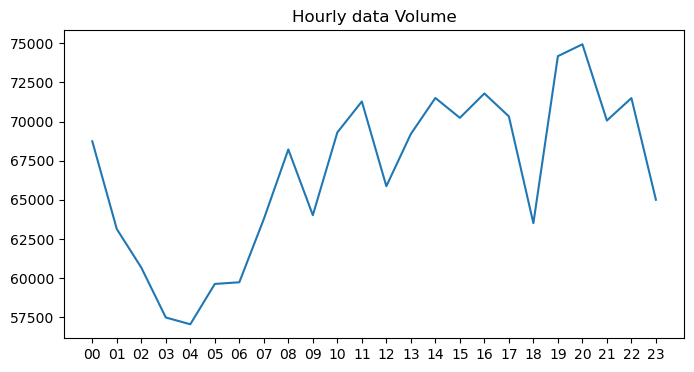

In [8]:
#一般，用matplotlib绘图的代码由3部分组成
#第一部分：创建图
import matplotlib.pyplot as plt
#创建一个图用plt.figure
#其中fig你可以想象是整张图,ax是图上的其中一个小画板（一个大图可以有多个小画板）
#而plt则是我们的画笔
fig     = plt.figure(1,(8,4))  # 创建1个画布，宽8英寸、高4英寸 
ax      = plt.subplot(111)     # 创建1行1列布局中的第1个子图
#告诉画笔，我们要在ax上画图
plt.sca(ax)

#第二部分：绘制
#用plt.plot画折线
plt.plot(hourcount['Stime'],hourcount['VehicleNum']) # x轴为小时，Y轴为对应的数据量


#第三部分：调整
plt.title('Hourly data Volume') # 设置标题
plt.show()

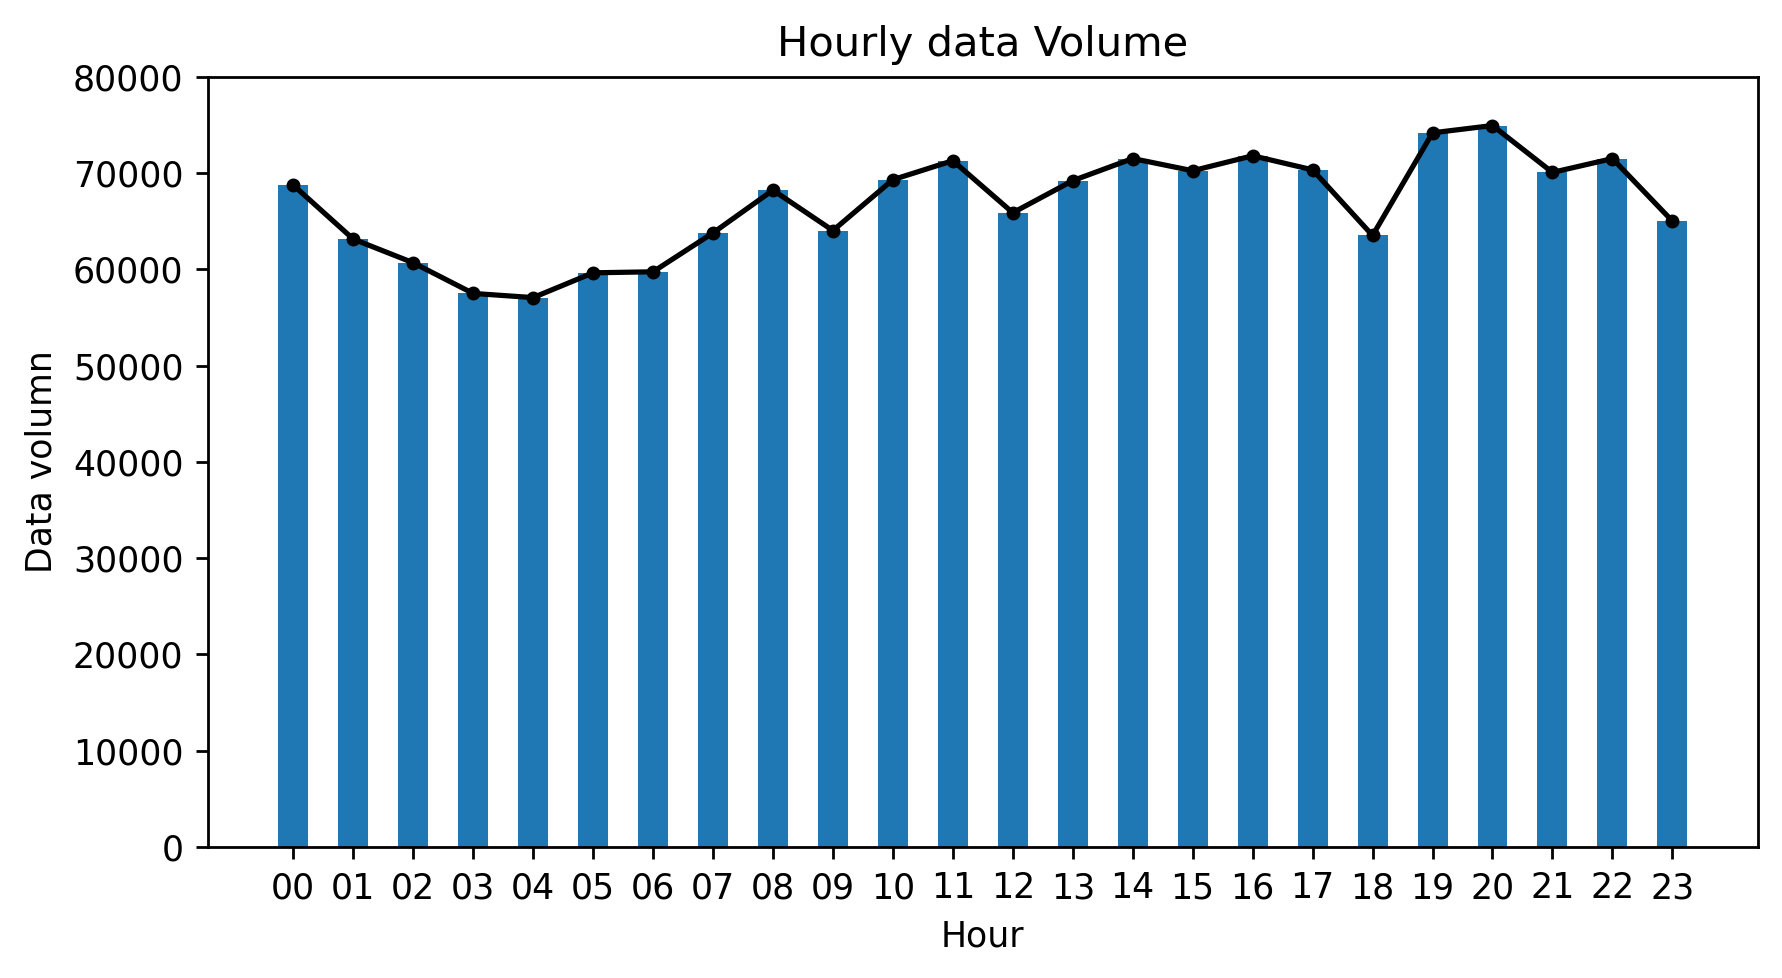

In [9]:
import matplotlib.pyplot as plt
fig     = plt.figure(1,(8,4),dpi = 250)    # dpi即分辨率，反应画面的清晰度
ax      = plt.subplot(111)
plt.sca(ax)

#折线图调整颜色加上数据点
plt.plot(hourcount['Stime'],hourcount['VehicleNum'],'k-',hourcount['Stime'],hourcount['VehicleNum'],'k.')
# k.表示用黑色小点绘制数据点；k-表示用黑色实线连接数据点
#加上条形图
plt.bar(hourcount['Stime'],hourcount['VehicleNum'],width =0.5)

plt.title('Hourly data Volume')

#把y轴起点固定在0
plt.ylim(0,80000)
plt.ylabel('Data volumn')
plt.xlabel('Hour')
plt.show()

seaborn是基于matplotlib的另一个绘图包，它提供了一些绘图的主题画出来的图更好看一点，也对一些功能进行集合，很多用plt多行代码才能画出来的图它只需要一行。另外，我们可以用seaborn的主题来画matplotlib

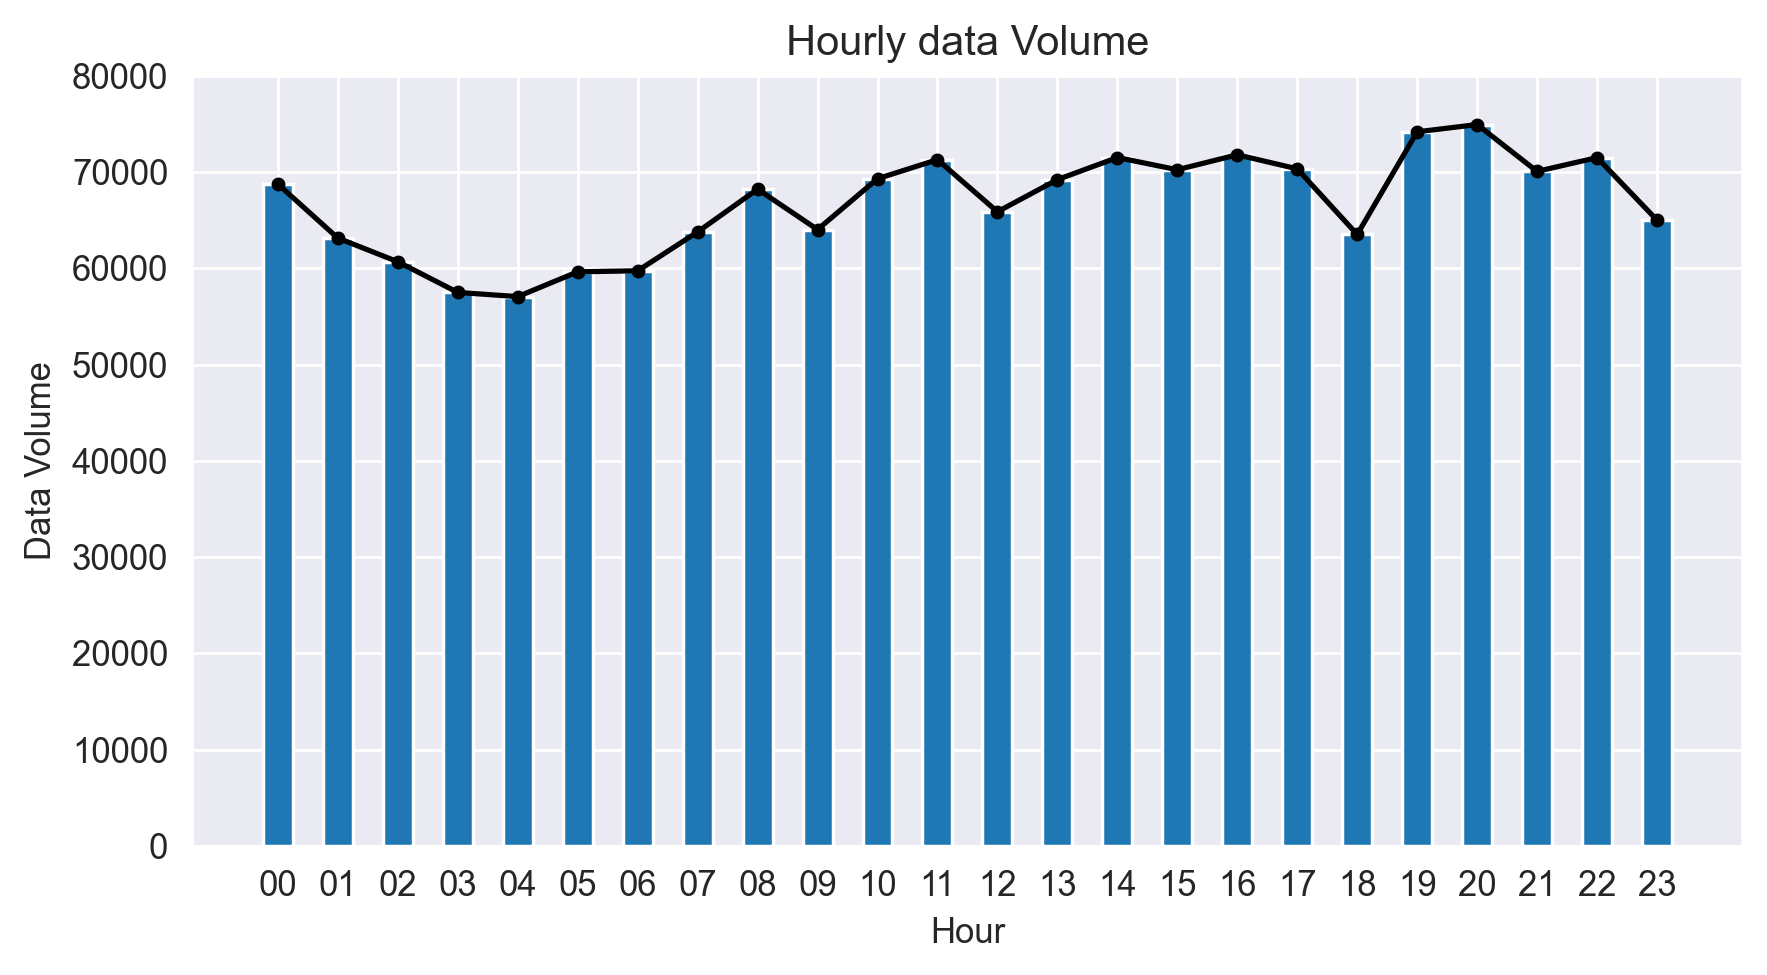

In [10]:
# 加上seaborn的主题
import seaborn as sns
# 设置全局绘图风格，自动优化视觉效果
sns.set_style('darkgrid',{"xtick.major.size": 10 , "ytick.major.size": 10})
# sns.set_style()设置全局绘图风格，自动优化配色、网格、字体、间距，无需手动调大量参数

import matplotlib.pyplot as plt
fig     = plt.figure(1,(8,4),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax)

plt.plot(hourcount['Stime'],hourcount['VehicleNum'],'k-',hourcount['Stime'],hourcount['VehicleNum'],'k.') # 绘制折线+每个数据点位置散点
plt.bar(hourcount['Stime'],hourcount['VehicleNum'],width =0.5)

plt.title('Hourly data Volume')

plt.ylim(0,80000)
plt.ylabel('Data Volume')
plt.xlabel('Hour')
plt.show()

订单的持续时间箱型图

In [11]:
# 过滤掉 TaxiOD 表中 Etime（结束时间）列为空值（NaN/NaT）的行，仅保留结束时间有效的行程记录
"""
.notna()
对列中每个元素逐一判断，非空值返回 True，空值返回 False；
可识别的空值包括：NaN（数值 / 字符串列空值）、NaT（时间类型列空值）、Python 原生 None；
最终返回一个和原列长度完全一致的布尔型 Series
"""
TaxiOD = TaxiOD[TaxiOD['Etime'].notna()]
# 同时建议把Stime也过滤，避免后续计算空值
TaxiOD = TaxiOD[TaxiOD['Stime'].notna()]

In [12]:
import pandas as pd
import time

tf = time.time() # 作为代码执行的起始时间点，最后用于计算总耗时
"""
.astype(str)：强制将整列数据转换为字符串类型。
目的：统一数据格式，为后续通过字符串切片提取「时、分、秒」做准备；
即使原列是时间类型、数值类型或混合类型，都会统一转为字符串，避免切片报错。
"""
et = TaxiOD['Etime'].astype(str)
st = TaxiOD['Stime'].astype(str)


# 分别提取结束时间的小时、分钟、秒，并转为数值类型
h_e = pd.to_numeric(et.str[:2], errors='coerce')
m_e = pd.to_numeric(et.str[3:5], errors='coerce')
s_e = pd.to_numeric(et.str[6:8], errors='coerce')

# pd.to_numeric()功能：将字符串转为数值（int/float）
# errors='coerce' 是核心容错参数：遇到无法转换的异常格式（比如空值、格式错误的时间），不会直接报错中断程序，而是自动转为 NaN（空值），保证代码健壮性
h_s = pd.to_numeric(st.str[:2], errors='coerce')
m_s = pd.to_numeric(st.str[3:5], errors='coerce')
s_s = pd.to_numeric(st.str[6:8], errors='coerce')

# 计算总秒数
e_total = h_e * 3600 + m_e * 60 + s_e
s_total = h_s * 3600 + m_s * 60 + s_s

# 订单时长
TaxiOD['order_time'] = e_total - s_total
# 跨天负数修正
# 如果计算出的时长为负数，说明行程跨越了当天零点（例如 23:50 出发，次日 00:10 到达，直接相减会得到负数）。
# 86400 是一天的总秒数（24 × 3600 = 86400），给负数值加上一天的秒数，就能得到正确的跨天行程时长
TaxiOD.loc[TaxiOD['order_time'] < 0, 'order_time'] += 86400
# 删除解析失败的空值行
# 前面 errors='coerce' 把格式错误的时间转成了 NaN，最终计算出的时长也会是 NaN，这一步就是把这些解析失败的无效订单全部剔除，保证结果数据全部有效
TaxiOD = TaxiOD.dropna(subset=['order_time'])

print('耗时：', time.time()-tf)
print(TaxiOD['order_time'].head())

耗时： 0.043477535247802734
0    81447.0
1    79755.0
2    72511.0
3    67078.0
4    58364.0
Name: order_time, dtype: float64


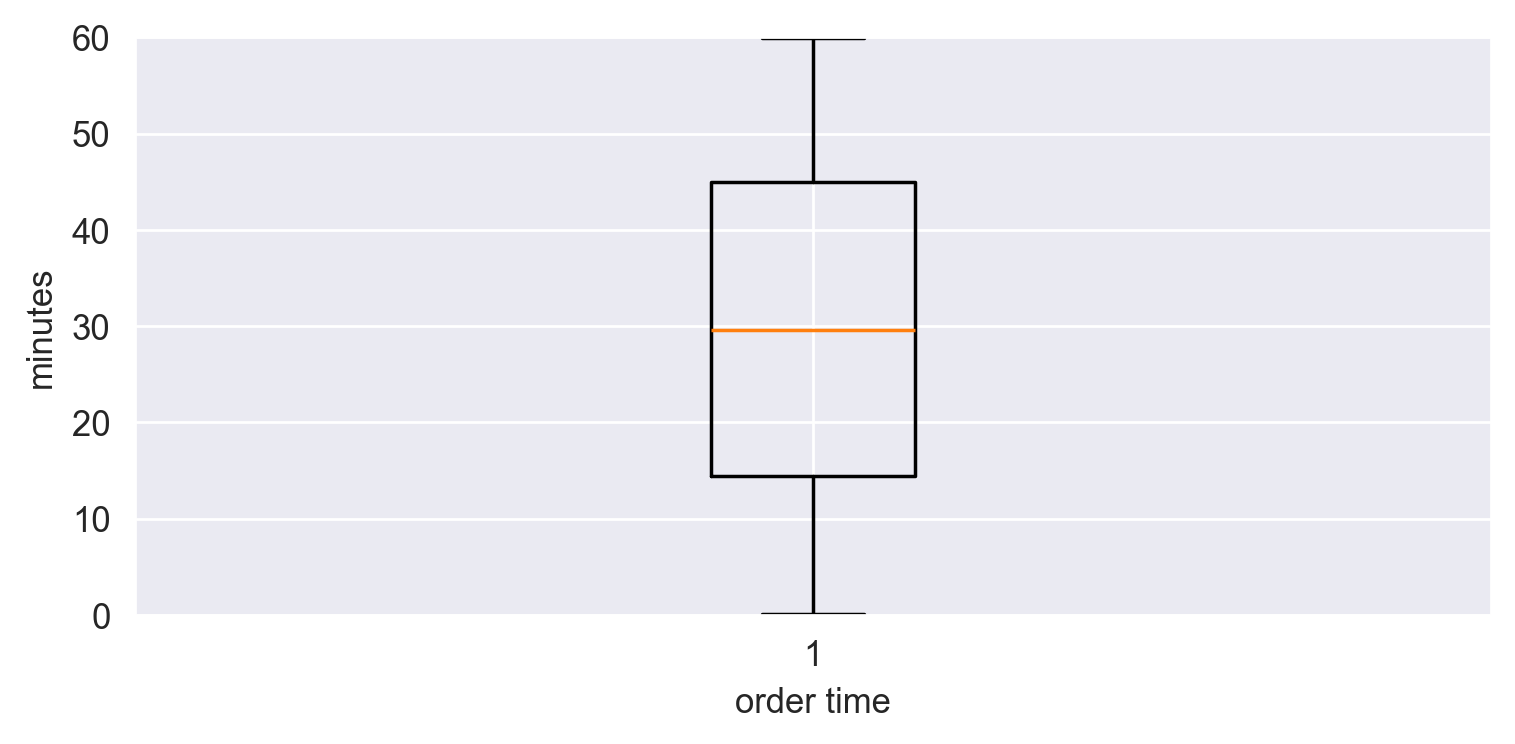

In [13]:
# %matplotlib inline：Jupyter 系列环境（Notebook/Lab）专属的魔法命令，作用是让 Matplotlib 绘制的图表直接嵌入在代码单元格的输出区域中
# 无需弹出独立的图形窗口；同时绘图后无需手动调用 plt.show() 也能自动渲染图表
%matplotlib inline
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(7, 3), dpi=250)
ax = plt.subplot(111)

# 筛选0~3600秒合法订单
valid_min = TaxiOD.loc[TaxiOD['order_time'].between(0, 3600), 'order_time'] / 60
# 通过布尔索引，取出值在 闭区间 [0, 3600] 内的数据，并将秒数转换为分钟，让后续图表的纵坐标单位更易读

# ax.boxplot()：坐标轴对象的箱线图绘制方法，输入一维数据序列即可生成箱线图
ax.boxplot(valid_min)
# 箱线图会自动计算并展示：最小值、下四分位数（25%）、中位数（50%）、上四分位数（75%）、最大值，以及超出上下须的异常值点

ax.set_ylabel('minutes')
ax.set_xlabel('order time')
ax.set_ylim(0, 60)
plt.show()

In [14]:
# 从 Stime（行程开始时间）字符串列中截取前两位字符，生成新的 Hour 列存储小时信息
TaxiOD['Hour'] = TaxiOD['Stime'].str[:2]

In [15]:
import pandas as pd
Taxi00 = pd.read_csv("E:/GIS_Learning/data/TaxiData-Sample.csv")
print(Taxi00.columns.tolist())

['22271', '22:54:04', '114.167', '22.718398999999998', '0', '0.1']


用两种方式绘图

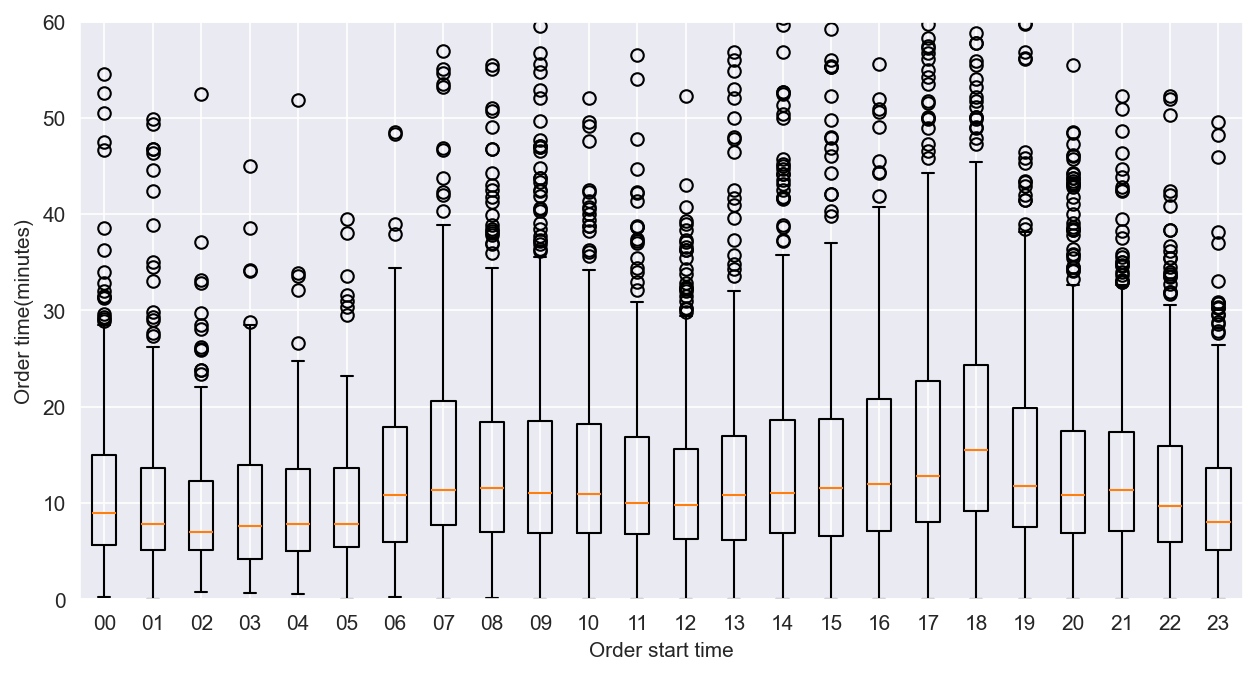

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# ========== 1. 读取原始GPS轨迹数据，手动设置列名 ==========
col_names = ['VehicleNum', 'Stime', 'Lng', 'Lat', 'OpenStatus', 'Speed']
taxi_gps = pd.read_csv("E:/GIS_Learning/data/TaxiData-Sample.csv", header=None, names=col_names)

# ========== 2. 时间格式转换 + 按车辆、时间排序 ==========
taxi_gps['Stime'] = pd.to_datetime(taxi_gps['Stime'], format='%H:%M:%S')
# pd.to_datetime()：将字符串格式的时间转为 Pandas 内置的 datetime 时间类型，方便后续做时间差计算
# format='%H:%M:%S'：指定输入格式为「时：分: 秒」，提升解析速度，避免格式歧义

taxi_gps = taxi_gps.sort_values(['VehicleNum', 'Stime']).reset_index(drop=True)
# ort_values(['VehicleNum', 'Stime'])：先按车辆编号分组，再按时间升序排列，是后续状态识别的核心前提：必须保证每辆车的 GPS 点是按时间先后顺序排列的
# reset_index(drop=True)：排序后原索引顺序被打乱，重置为从 0 开始的连续新索引，drop=True 表示丢弃旧索引，避免多余列

# ========== 3. 从轨迹中提取每一笔订单，计算订单时长 ==========
# 识别载客状态变化：0→1是订单开始，1→0是订单结束
# 核心原理：用相邻行差分识别状态跳变，从而定位订单的开始和结束
taxi_gps['status_change'] = taxi_gps.groupby('VehicleNum')['OpenStatus'].diff()
# groupby('VehicleNum')：按车辆分组，只在同一辆车内部计算相邻行的差值
# ['OpenStatus'].diff()：计算当前行载客状态 - 上一行载客状态的差值
order_starts = taxi_gps[taxi_gps['status_change'] == 1].reset_index(drop=True)
order_ends = taxi_gps[taxi_gps['status_change'] == -1].reset_index(drop=True)
"""
上一行是 0（空车）、当前行是 1（载客）：差值 = 1-0 = 1 → 接到乘客，订单开始
上一行是 1（载客）、当前行是 0（空车）：差值 = 0-1 = -1 → 乘客下车，订单结束
状态不变：差值 = 0 → 非订单节点
每辆车的第一行没有上一行，差值为 NaN
reset_index 重置索引，方便后续按顺序匹配
"""

# 匹配每辆车的订单起止，生成订单表
orders = []
for vid in taxi_gps['VehicleNum'].unique(): # .unique() 取出所有不重复的车辆编号，逐车处理
    starts = order_starts[order_starts['VehicleNum'] == vid]
    ends = order_ends[order_ends['VehicleNum'] == vid]
    min_len = min(len(starts), len(ends)) # 实际数据中经常出现「最后一个状态是载客，没有结束点」或「第一个点是结束状态」取最小长度对齐以避免索引越界报错
    for i in range(min_len):
        start_t = starts.iloc[i]['Stime']
        end_t = ends.iloc[i]['Stime']
        duration = (end_t - start_t).total_seconds()
        if duration > 0: # 过滤掉时长为 0 或负数的异常订单
            orders.append({'start_time': start_t, 'order_time': duration})

Taxi00 = pd.DataFrame(orders) # 清洗数据转成DataFrame

# ========== 4. 提取订单开始的小时字段 ==========
Taxi00['Hour'] = Taxi00['start_time'].dt.strftime('%H')
# .dt：datetime 类型列的专属访问器，用于调用时间相关方法
# .strftime('%H')：将时间格式化为两位小时字符串（如 08、14、23），用于后续按小时分组

# ========== 5. 和教程完全一致的箱线图绘制 ==========
hour = Taxi00['Hour'].drop_duplicates().sort_values()
# drop_duplicates()：去重，得到所有出现过的小时值
# sort_values()：按小时排序，保证 x 轴从早到晚顺序正确，而不是按数据出现顺序乱序排列

datas = []
for i in range(len(hour)):
    datas.append(Taxi00[Taxi00['Hour'] == hour.iloc[i]]['order_time'] / 60)

plt.figure(figsize=(10, 5), dpi=150)
plt.boxplot(datas) # 一次性绘制多个箱线，每个箱线对应一个小时的订单时长分布，展示中位数、四分位、异常值等统计信息
plt.xticks(range(1, len(hour)+1), list(hour)) # 把刻度位置和小时标签一一对应，位置从 1 到 n，标签对应排序后的小时字符串，保证对齐准确
plt.ylabel('Order time(minutes)')
plt.xlabel('Order start time')
plt.ylim(0, 60)
plt.show()

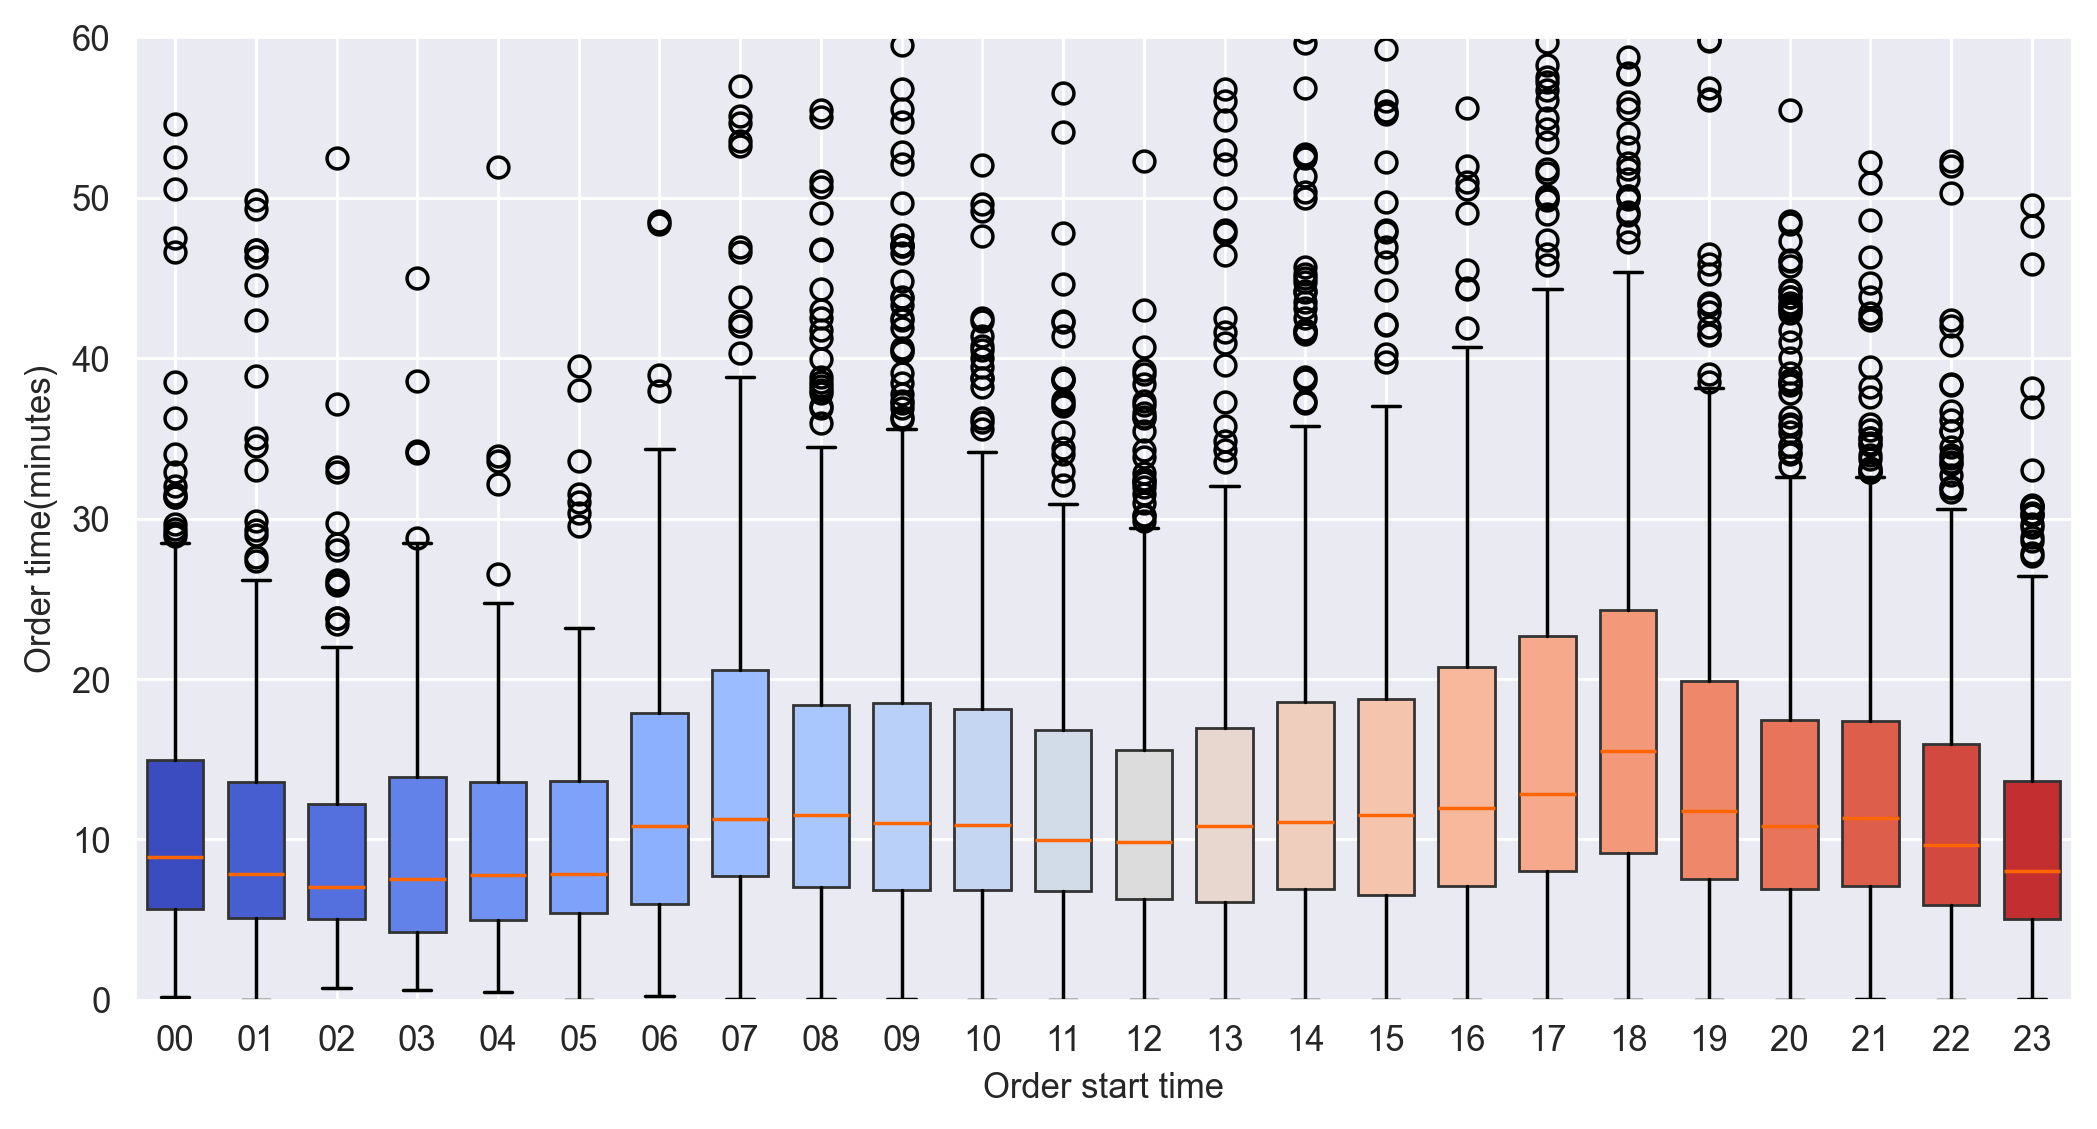

In [17]:
import matplotlib.pyplot as plt
%matplotlib inline

# 数据预处理（和之前保持一致）
Taxi00['order_time_min'] = Taxi00['order_time'] / 60
Taxi00['Hour'] = pd.Categorical(
    Taxi00['Hour'],
    categories=[f'{i:02d}' for i in range(24)],
    ordered=True
)

# 按小时分组准备数据
hour_list = sorted(Taxi00['Hour'].unique())
datas = [Taxi00[Taxi00['Hour'] == h]['order_time_min'] for h in hour_list]

# 创建画布
plt.figure(figsize=(10, 5), dpi=250)

# 绘制原生箱线图，patch_artist=True 是填充颜色的必要参数
box = plt.boxplot(
    datas,
    patch_artist=True,
    widths=0.7,
    medianprops={'color': '#ff6600'}  # 中位数线设为橙色，和教程一致
)

# 生成渐变颜色：coolwarm 蓝→红冷暖渐变，24个箱体一一对应
gradient_colors = plt.cm.coolwarm([i / len(datas) for i in range(len(datas))])

# 逐个给箱体上色，保证一一对应
for patch, color in zip(box['boxes'], gradient_colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('#333333')  # 深灰色细边框，更精致
    patch.set_linewidth(0.8)

# 坐标轴设置
plt.xticks(range(1, len(hour_list)+1), hour_list)
plt.ylabel('Order time(minutes)')
plt.xlabel('Order start time')
plt.ylim(0, 60)
plt.show()